# Preprocesamiento previo a la selección de variables

**Objetivo.** Dejar las predictoras diarias limpias, completas y auditables antes de crear y seleccionar variables. El modelo pronostica, al cierre del día **D** (23:59), el consumo de frío de **D+1**.

**Punto de partida.**

* `data/processed/dataset_trabajo.csv`: el dataset horario con las correcciones de fechas del EDA (bloques repetidos, typos de hora, solapamiento entre Excel y días inválidos).
* Las decisiones estructurales de `notebooks/eda.ipynb`, exportadas a `results/eda/`: qué columnas se excluyen por ser metadatos, componentes o proxies del frío, columnas calculadas por diferencia o copias de otra hoja, y qué columnas renombradas se unen. Se aplican como primer paso y no se vuelven a discutir acá.

**Reglas contra la fuga de información:**

1. La división es cronológica (70 / 15 / 15) y se fija **antes** de cualquier tratamiento.
2. **Todo lo que se estima o se decide en esta notebook usa solo fechas de Train**: umbrales, medianas, métodos elegidos, escalas, LOF y los análisis de las secciones 11 a 13. Validation y Test solo se transforman con lo aprendido en Train.
3. Toda transformación es **causal**: el valor del día *t* depende solo de días ≤ *t*. Por eso se puede transformar la serie completa de una sola vez. En la sección 9 se verifica.
4. El target `y` nunca se modifica.

Toda la lógica vive en `src/preprocessing_pipeline.py`. Esta notebook ajusta cada paso por separado para mostrar sus decisiones y, al final, comprueba que el resultado coincide con el script.

| Sección | Contenido |
|---|---|
| 1 | Datos de partida y división cronológica |
| 2 | Paso 0: columnas que decidió la EDA |
| 3 | Panorama de nulos en Train |
| 4 | Paso 1: columnas vacías o constantes en Train |
| 5 | Paso 2: columnas duplicadas en Train |
| 6 | Paso 3: clasificación y filtrado por nulos |
| 7 | Paso 4: outliers univariados |
| 8 | Paso 5: imputación con búsqueda del mejor método |
| 9 | Verificación de causalidad e impacto por partición |
| 10 | Análisis multivariado con LOF |
| 11 | Producción del mismo día y consumo de frío |
| 12 | Hipótesis: las metas dependen de la temperatura y de la producción |
| 13 | Ciclo anual, regímenes e interacciones: evidencia para crear variables |
| 14 | Exportación y comparación con el script |
| 15 | Conclusiones y decisiones pendientes |

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.pipeline import Pipeline

# La notebook puede abrirse desde la raíz o desde la carpeta notebooks.
raiz = Path.cwd()
if raiz.name == "notebooks":
    raiz = raiz.parent
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

from src import eda
from src import preprocessing_pipeline as pp
from src.preprocessing_pipeline import (
    AnalisisLOF, AplicarDecisionesEDA, Config, DescartarDuplicadas, DescartarNoInformativas,
    FiltrarPorNulos, ImputarNulos, TratarOutliersUnivariados,
)

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 200)

# Estilo de gráficos: marcas finas, grilla tenue, paleta categórica en orden fijo.
COLORES = {"train": "#2a78d6", "validation": "#eb6834", "test": "#1baf7a"}
SERIE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
plt.rcParams.update({
    "figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 1.2,
    "axes.titleweight": "bold", "axes.titlesize": 11,
})

cfg = Config()
display(pd.Series(vars(cfg), name="valor").to_frame())

,valor
proporciones,"(0.7, 0.15, 0.15)"
columnas_obligatorias,"(Frio (Kw)_Consolidado EE,)"
hojas_preferidas_duplicados,"(_Totalizadores ,)"
proteger_de_filtro_nulos,"(^Meta ,)"
dias_recientes,60
max_nulos_train,0.3
dias_bloque,7
patron_kpi_por_hl,/\s*H[lL]
patron_produccion,^H[lL]
min_cobertura_no_aplica,0.95


## 1. Datos de partida y división cronológica

`cargar_datos_diarios` verifica el SHA-256 de `dataset_trabajo.csv` contra `data/checksums.json`, toma el registro de las 23:59 de cada día (los totalizadores se reinician a medianoche, así que el cierre es el total diario) y construye `y` = frío de D+1 buscando la fecha calendario siguiente. La división reutiliza las funciones del pipeline de entrega, así que los cortes son los mismos que en Fase 2.

In [2]:
X, y, cortes, sha = pp.cargar_datos_diarios(
    pp.lh.DEFAULT_INPUT_CSV, pp.lh.DEFAULT_CHECKSUMS_JSON, cfg)
fin_train = cortes["train"][1]
particion = pp._particion(X.index, y, cortes)

print(f"SHA-256 de entrada verificado: {sha[:16]}...")
print(f"Días: {len(X)} | columnas: {X.shape[1]} | días con y: {y.notna().sum()}")
display(pd.DataFrame({
    "inicio": {p: a.date() for p, (a, b) in cortes.items()},
    "fin": {p: b.date() for p, (a, b) in cortes.items()},
    "días": particion.value_counts(),
}))

SHA-256 de entrada verificado: bd015abb722ba215...
Días: 1172 | columnas: 419 | días con y: 1140


,inicio,fin,días
sin_etiqueta,NaN,NaN,32
test,2023-04-30,2023-10-24,171
train,2020-07-01,2022-10-26,798
validation,2022-10-27,2023-04-29,171


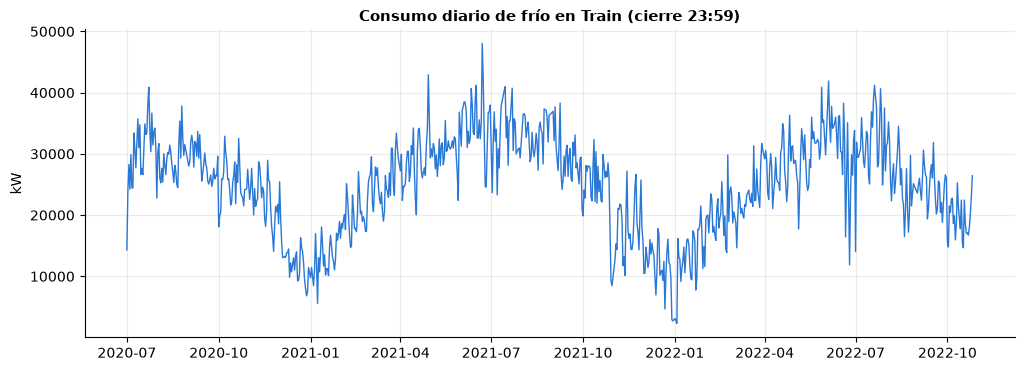

In [3]:
# Solo Train: la notebook no mira el objetivo de Validation ni de Test.
fig, ax = plt.subplots()
ax.plot(X.loc[:fin_train].index, X.loc[:fin_train, pp.COL_FRIO], color=COLORES["train"], lw=1)
ax.set_title("Consumo diario de frío en Train (cierre 23:59)")
ax.set_ylabel("kW")
plt.show()

Los días sin etiqueta (`sin_etiqueta`) son cierres cuyo día siguiente no está en el dataset: en 16 casos porque la limpieza descartó D+1 por inválido, y en los otros 16 porque D+1 no existe en ningún Excel (los 31 de marzo, mayo, octubre y diciembre, y del 29 al 31 de agosto; ver la sección 1.1 de `eda.ipynb`). No se usan como ejemplos supervisados, pero sí como historia para los métodos que miran días anteriores. Los 21 que caen antes del fin de Train entran al ajuste de los pasos.

## Mecánica de los pasos

Cada paso es una clase con `fit` y `transform`. La función `ajustar` lo ajusta **solo con las fechas de Train** y transforma la serie completa. Es exactamente lo que hace `Pipeline` en el script; acá lo hacemos de a un paso para inspeccionar cada uno.

In [4]:
pasos_ajustados = []

def ajustar(nombre, paso, X_actual):
    # Ajusta con Train, transforma toda la serie y guarda el paso.
    X_fit = X_actual.loc[:fin_train]
    paso.fit(X_fit, y.reindex(X_fit.index))
    pasos_ajustados.append((nombre, paso))
    X_nuevo = paso.transform(X_actual)
    print(f"{nombre}: {X_actual.shape[1]} -> {X_nuevo.shape[1]} columnas")
    return X_nuevo

## 2. Paso 0: columnas que decidió la EDA

La EDA (sección 1.2 de `eda.ipynb`) decidió qué columnas no llegan al preprocesamiento y cuáles son la misma medición con otro nombre. Son decisiones sobre la estructura de la planilla, no sobre los datos de Train, así que este paso no estima nada: aplica la lista que exporta `src/eda.py`. `cargar_decisiones` verifica que esa lista se haya calculado con esta misma versión de `dataset_trabajo.csv`.

| Categoría | Qué se excluye | Por qué |
|---|---|---|
| Metadatos | Identificadores, columnas sin encabezado, hora del último dato | No son mediciones |
| Componentes del frío | 7 compresores Mycom, 3 grupos de condensadores, 2 bombas de glicol | `Frio (Kw)` es su suma exacta; su reparto cambia por la rotación de los compresores |
| Proxies del frío | Sala de Máquinas, Servicios, Planta y KW Gral Planta | Contienen al frío del mismo día |
| Calculadas por diferencia | `Resto Serv`, `Restos Planta`, Servicios de agua y de aire | Tienen lecturas negativas, imposibles en un medidor |
| Copias | La misma medición en una hoja *Consolidado* y en una *Totalizadores* | Idénticas en toda la serie |
| Renombradas | Vapor L5 (dos hojas) y `Tot L3, L4 y Planta de CO2` | La serie vieja completa a la nueva |

In [5]:
decisiones = eda.cargar_decisiones()  # verifica que correspondan a este dataset_trabajo.csv
X0 = ajustar("aplicar_decisiones_eda", AplicarDecisionesEDA(decisiones), X)
rep0 = pasos_ajustados[-1][1].reporte_
display(pd.crosstab(rep0["categoria"].replace("", "—"), rep0["decision"], margins=True, margins_name="Total"))
display(rep0.loc[rep0["decision"] == "unificar", ["columna", "unida_en", "motivo"]])

aplicar_decisiones_eda: 419 -> 321 columnas


decision,conservar,descartar,unificar,Total
categoria,,,,
componentes_frio,0,12,0,12
copias,0,32,0,32
metadatos,0,42,0,42
proxies_frio,0,5,0,5
renombradas,0,0,3,3
residuales,0,4,0,4
—,321,0,0,321
Total,321,95,3,419


,columna,unida_en,motivo
409,Tot L3. L4 y Planta de CO2_Totalizadores Glicol,"Tot L3, L4 y Planta de CO2_Totalizadores Glicol","Misma medición que 'Tot L3, L4 y Planta de CO2_Totalizadores Glicol' (Salto de nivel: ..."
414,Vapor _Vapor_L5 (KG)_Consolidado GasVapor,Vapor_L5 (KG)_Consolidado GasVapor,Misma medición que 'Vapor_L5 (KG)_Consolidado GasVapor' (Nivel continuo); se une a ella
415,Vapor _Vapor_L5 (KG)_Totalizadores Gas y Vapor,Vapor_L5 (KG)_Totalizadores Gas y Vapor,Misma medición que 'Vapor_L5 (KG)_Totalizadores Gas y Vapor' (Nivel continuo); se une ...


## 3. Panorama de nulos en Train

Antes de tratar nada miramos cuántos nulos hay en Train, en las columnas que dejó la EDA, y cómo se distribuyen en el tiempo. El patrón temporal es lo que permite clasificarlos.

In [6]:
X_train_crudo = X0.loc[:fin_train]
nulos_train = X_train_crudo.isna().mean()
rangos = pd.cut(nulos_train, [-0.01, 0, 0.05, 0.20, 0.50, 0.99, 1.0],
                labels=["0 %", "≤5 %", "5–20 %", "20–50 %", "50–99 %", "100 %"])
hoja = pd.Series({c: c.rsplit("_", 1)[-1] for c in X0.columns})

display(rangos.value_counts().sort_index().rename_axis("Nulos en Train").to_frame("Columnas"))
display(pd.DataFrame({"columnas": hoja.value_counts(),
                      "% nulos medio en Train": nulos_train.groupby(hoja).mean().mul(100).round(1)})
        .sort_values("% nulos medio en Train", ascending=False))

,Columnas
Nulos en Train,
0 %,192
≤5 %,31
5–20 %,20
20–50 %,68
50–99 %,9
100 %,1


,columnas,% nulos medio en Train
Auxiliar,1,86.0
Totalizadores Glicol,8,45.2
Consolidado KPI,103,24.3
Consolidado Agua,14,18.6
Consolidado GasVapor,12,10.9
Totalizadores Aire,9,9.2
Consolidado Produccion,6,7.2
Totalizadores Produccion,39,6.6
Totalizadores Gas y Vapor,21,3.8
Consolidado EE,13,0.0


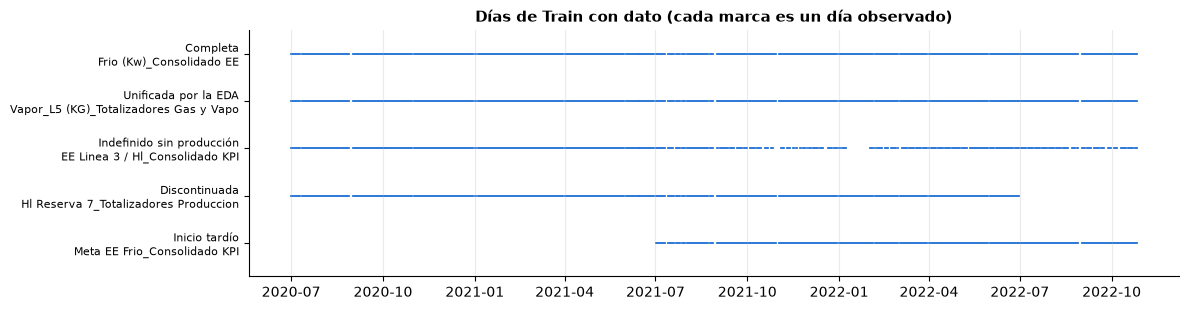

In [7]:
# Presencia en Train de columnas representativas de cada tipo de nulo.
ejemplos = {
    "Meta EE Frio_Consolidado KPI": "Inicio tardío",
    "Hl Reserva 7_Totalizadores Produccion": "Discontinuada",
    "EE Linea 3 / Hl_Consolidado KPI": "Indefinido sin producción",
    "Vapor_L5 (KG)_Totalizadores Gas y Vapor": "Unificada por la EDA",
    "Frio (Kw)_Consolidado EE": "Completa",
}
X0_train = X0.loc[:fin_train]
fig, ax = plt.subplots(figsize=(12, 3.2))
for i, (col, etiqueta) in enumerate(ejemplos.items()):
    presente = X0_train[col].notna()
    ax.scatter(X0_train.index[presente], np.full(presente.sum(), i), s=2, color="#2a78d6", marker="|")
ax.set_ylim(-0.7, len(ejemplos) - 0.5)
ax.set_yticks(range(len(ejemplos)), [f"{e}\n{c[:38]}" for c, e in ejemplos.items()], fontsize=8)
ax.set_title("Días de Train con dato (cada marca es un día observado)")
ax.grid(axis="y", alpha=0)
plt.show()

Los nulos **no son homogéneos**. Hay columnas que no existían en un Excel (empiezan el 2021-07-02 o el 2022-07-01), columnas que se dejaron de registrar, y KPI por hectolitro que solo faltan los días sin producción. Cada tipo pide un tratamiento distinto, así que imputarlos todos con la mediana sería un error.

## 4. Paso 1: columnas vacías o constantes en Train

Se descartan las columnas **vacías** o **constantes en Train** (por ejemplo, siempre 0): no aportan variación para aprender. Esta decisión sí depende de los datos, por eso se toma con Train: una columna que recién empieza a variar en Validation no sirve para entrenar. Los metadatos ya no se tratan acá porque los excluyó la EDA.

In [8]:
X1 = ajustar("descartar_no_informativas", DescartarNoInformativas(cfg), X0)
rep1 = pasos_ajustados[-1][1].reporte_
motivo_corto = rep1["motivo"].str.replace(r" \(.*\)$", "", regex=True).replace("", "—")
display(pd.crosstab(motivo_corto, rep1["decision"]).rename_axis("Motivo"))
display(rep1[rep1["decision"] == "descartar"].sample(8, random_state=0))

descartar_no_informativas: 321 -> 296 columnas


decision,conservar,descartar
Motivo,,
Constante en Train,0,24
Vacía en Train,0,1
—,296,0


,columna,decision,motivo
115,HL Mosto Indio_Totalizadores Produccion,descartar,Constante en Train (valor 0.0)
109,HL Mosto Budweiser_Totalizadores Produccion,descartar,Constante en Train (valor 0.0)
266,Tot_Vapor_Caldera 3_Totalizadores Gas y Vapor,descartar,Constante en Train (valor 0.0)
219,Red Barriles_Totalizadores Agua,descartar,Constante en Train (valor 0.0)
134,Hl Mosto Blue Moon_Totalizadores Produccion,descartar,Constante en Train (valor 0.0)
284,Fuel Oil Tk2 (Kg)_Totalizadores Gas y Vapor,descartar,Constante en Train (valor 0.0)
230,Agua Filt FMaCist CE_Totalizadores Agua,descartar,Constante en Train (valor 0.0)
317,Hl Reserva 7_Totalizadores Produccion,descartar,Constante en Train (valor 0.0)


## 5. Paso 2: columnas duplicadas en Train

La EDA ya excluyó las copias en toda la serie: la misma medición en una hoja *Consolidado* y en una *Totalizadores*. Acá se buscan columnas que coinciden **solo en Train** (mismos valores con 6 decimales y mismos nulos): aunque después difieran, el modelo no puede distinguirlas al aprender. Entre copias se conserva la columna obligatoria (el frío), después la versión de una hoja *Totalizadores* y, si no, la primera en el orden original.

La correlación alta entre columnas *distintas* se deja para la selección de variables.

In [9]:
X3 = ajustar("descartar_duplicadas", DescartarDuplicadas(cfg), X1)
rep3 = pasos_ajustados[-1][1].reporte_
descartadas = rep3[rep3["decision"] == "descartar"]
print(f"Columnas que coinciden con otra solo en Train: {len(descartadas)}")
if len(descartadas):
    display(descartadas)

descartar_duplicadas: 296 -> 296 columnas
Columnas que coinciden con otra solo en Train: 0


**Lectura.** Ninguna. Antes de mover las decisiones a la EDA, este paso encontraba 33 copias en Train: 32 lo son en toda la serie y ahora las quita la EDA, y la restante es `KW Gral Planta` de la hoja *Consolidado EE*, que la EDA excluye como medidor que contiene al frío. El paso se conserva porque una copia que solo coincide en Train podría aparecer con otros datos.

## 6. Paso 3: clasificación y filtrado por nulos

`clasificar_nulos` separa los nulos de cada columna en componentes y asigna el tipo dominante:

| Tipo | Regla | Mecanismo probable |
|---|---|---|
| `vacia` | 100 % nulos | No se registra nunca |
| `discontinuada` | sin datos en los últimos 60 días de Train | No estará disponible al predecir |
| `inicio_tardio` | la mayoría de los nulos son previos al primer dato | La columna no existía en ese Excel |
| `no_aplica_sin_produccion` | KPI "/Hl" cuyos nulos caen (≥ 95 %) en días con producción ≤ 0 | MNAR: el cociente no está definido |
| `bloques` | racha de ≥ 7 días con nulos | Falla prolongada de registro |
| `MCAR` | rachas cortas | Faltantes aislados |

Además, para cada columna se compara con Mann-Whitney el `y` de los días con nulo y el de los días sin nulo. Un p-valor bajo indica que el faltante no es completamente al azar.

**Se descartan**: columnas vacías, las discontinuadas y las que superan el 30 % de nulos **efectivos** en Train. Los indefinidos por falta de producción no cuentan como faltantes, porque su valor es conocido.

Las **metas** (`Meta *`) están protegidas del umbral de nulos (`proteger_de_filtro_nulos`). Les falta el primer año completo porque no estaban en el Excel 2020-2022, pero se fijan por adelantado (se conocen al cierre de D) y queremos probar la hipótesis de la sección 12. Igual se descartan si están vacías o discontinuadas.

In [10]:
X4 = ajustar("filtrar_por_nulos", FiltrarPorNulos(cfg), X3)
rep4 = pasos_ajustados[-1][1].reporte_
display(pd.crosstab(rep4["tipo"], rep4["decision"], margins=True, margins_name="Total"))

filtrar_por_nulos: 296 -> 267 columnas


decision,conservar,descartar,Total
tipo,,,
completa,171,0,171
discontinuada,0,3,3
inicio_tardio,44,26,70
no_aplica_sin_produccion,52,0,52
Total,267,29,296


In [11]:
# Verificación de la regla "indefinido sin producción": cada nulo del KPI cae en un día sin producción.
kpi, denominador = "EE Linea 3 / Hl_Consolidado KPI", "Hl Cerveza L3_Consolidado Produccion"
tr = X.loc[:fin_train]
print(pd.crosstab(tr[kpi].isna().map({True: "KPI nulo", False: "KPI con dato"}),
                  (tr[denominador].fillna(0) > 0).map({True: "con producción", False: "sin producción"})))

columnas_ver = ["columna", "tipo", "pct_nulos", "pct_nulos_efectivos", "n_sin_produccion",
                "denominador", "p_valor_y", "decision", "motivo"]
display(rep4.loc[rep4["tipo"] == "no_aplica_sin_produccion", columnas_ver].head(6))

Hl Cerveza L3_Consolidado Produccion  con producción  sin producción
EE Linea 3 / Hl_Consolidado KPI                                     
KPI con dato                                     641              73
KPI nulo                                           0             105


,columna,tipo,pct_nulos,pct_nulos_efectivos,n_sin_produccion,denominador,p_valor_y,decision,motivo
0,EE Planta / Hl_Consolidado KPI,no_aplica_sin_produccion,0.010989,0.0,9,Hl de Mosto_Consolidado Produccion,NaN,conservar,
1,EE Elaboracion / Hl_Consolidado KPI,no_aplica_sin_produccion,0.010989,0.0,9,Hl de Mosto_Consolidado Produccion,NaN,conservar,
2,EE Bodega / Hl_Consolidado KPI,no_aplica_sin_produccion,0.010989,0.0,9,Hl de Mosto_Consolidado Produccion,NaN,conservar,
3,EE Cocina / Hl_Consolidado KPI,no_aplica_sin_produccion,0.056166,0.0,46,Hl de Mosto_Consolidado Produccion,NaN,conservar,
4,EE Envasado / Hl_Consolidado KPI,no_aplica_sin_produccion,0.010989,0.0,9,Hl de Mosto_Consolidado Produccion,NaN,conservar,
5,EE Linea 2 / Hl_Consolidado KPI,no_aplica_sin_produccion,0.092796,0.0,76,HL Mosto Amstel_Totalizadores Produccion,NaN,conservar,


In [12]:
print("Columnas descartadas por motivo:")
motivo4 = rep4.loc[rep4["decision"] == "descartar", "motivo"].str.replace(
    r"^\d+\.\d+% de nulos efectivos.*", "Más de 30 % de nulos efectivos en Train", regex=True)
display(motivo4.value_counts().to_frame("columnas"))
display(rep4.loc[rep4["decision"] == "descartar", columnas_ver].sort_values("pct_nulos_efectivos").head(10))

Columnas descartadas por motivo:


,columnas
motivo,
Más de 30 % de nulos efectivos en Train,26
Estructural: dejó de registrarse antes del fin de Train,3


,columna,tipo,pct_nulos,pct_nulos_efectivos,n_sin_produccion,denominador,p_valor_y,decision,motivo
129,Cocimientos Diarios_Totalizadores Produccion,inicio_tardio,0.305250,0.305250,0,NaN,1.614089e-07,descartar,30.5% de nulos efectivos en Train (> 30%)
130,Nivel Silo Bagazo Norte (1)_Totalizadores Produccion,inicio_tardio,0.366300,0.366300,0,NaN,8.211606e-04,descartar,36.6% de nulos efectivos en Train (> 30%)
131,Nivel Silo Bagazo Sur (2)_Totalizadores Produccion,inicio_tardio,0.366300,0.366300,0,NaN,8.211606e-04,descartar,36.6% de nulos efectivos en Train (> 30%)
274,Tot Aire Expulsion_Totalizadores Aire,inicio_tardio,0.415140,0.415140,0,NaN,7.068731e-01,descartar,41.5% de nulos efectivos en Train (> 30%)
275,Tot Aire Servicio Logistica_Totalizadores Aire,inicio_tardio,0.415140,0.415140,0,NaN,7.068731e-01,descartar,41.5% de nulos efectivos en Train (> 30%)
56,Agua Lavadora L3 / Hl_Consolidado KPI,inicio_tardio,0.434676,0.434676,0,NaN,3.477474e-01,descartar,43.5% de nulos efectivos en Train (> 30%)
57,Agua Paste L3 / Hl_Consolidado KPI,inicio_tardio,0.434676,0.434676,0,NaN,3.477474e-01,descartar,43.5% de nulos efectivos en Train (> 30%)
50,Aire Expulsion / Hl_Consolidado KPI,inicio_tardio,0.490842,0.434676,46,Hl de Mosto_Consolidado Produccion,9.160174e-01,descartar,43.5% de nulos efectivos en Train (> 30%)
190,Agua Paste L3_Consolidado Agua,inicio_tardio,0.434676,0.434676,0,NaN,3.477474e-01,descartar,43.5% de nulos efectivos en Train (> 30%)
191,Agua Lavadora L3_Consolidado Agua,inicio_tardio,0.434676,0.434676,0,NaN,3.477474e-01,descartar,43.5% de nulos efectivos en Train (> 30%)


In [13]:
display(rep4.loc[rep4["protegida"], columnas_ver].head(5))
print(f"Metas protegidas y conservadas: {int((rep4['protegida'] & (rep4['decision'] == 'conservar')).sum())}")

,columna,tipo,pct_nulos,pct_nulos_efectivos,n_sin_produccion,denominador,p_valor_y,decision,motivo
58,Meta EE Planta_Consolidado KPI,inicio_tardio,0.434676,0.434676,0,NaN,0.347747,conservar,Protegida del umbral de nulos
59,Meta Agua Planta_Consolidado KPI,inicio_tardio,0.434676,0.434676,0,NaN,0.347747,conservar,Protegida del umbral de nulos
60,Meta ET Planta_Consolidado KPI,inicio_tardio,0.434676,0.434676,0,NaN,0.347747,conservar,Protegida del umbral de nulos
61,Meta Aire Planta_Consolidado KPI,inicio_tardio,0.434676,0.434676,0,NaN,0.347747,conservar,Protegida del umbral de nulos
62,Meta Agua Elab_Consolidado KPI,inicio_tardio,0.434676,0.434676,0,NaN,0.347747,conservar,Protegida del umbral de nulos


Metas protegidas y conservadas: 43


In [14]:
# Asociación de los nulos con y (solo columnas conservadas con nulos efectivos).
con_test = rep4[(rep4["decision"] == "conservar") & rep4["p_valor_y"].notna()]
print(f"Columnas conservadas con test de asociación: {len(con_test)}")
display(con_test[columnas_ver].sort_values("p_valor_y").head(8))

Columnas conservadas con test de asociación: 47


,columna,tipo,pct_nulos,pct_nulos_efectivos,n_sin_produccion,denominador,p_valor_y,decision,motivo
290,Tot Trasiego_Totalizadores Glicol,inicio_tardio,0.084249,0.084249,0,NaN,5.977197e-10,conservar,
26,Agua Linea 5/Hl_Consolidado KPI,no_aplica_sin_produccion,0.340659,0.024420,259,HL Mosto Amstel_Totalizadores Produccion,2.651167e-05,conservar,
48,Aire L5 / Hl_Consolidado KPI,no_aplica_sin_produccion,0.340659,0.024420,259,HL Mosto Amstel_Totalizadores Produccion,2.651167e-05,conservar,
38,ET Linea 5/Hl_Consolidado KPI,no_aplica_sin_produccion,0.340659,0.024420,259,HL Mosto Amstel_Totalizadores Produccion,2.651167e-05,conservar,
59,Meta Agua Planta_Consolidado KPI,inicio_tardio,0.434676,0.434676,0,NaN,3.477474e-01,conservar,Protegida del umbral de nulos
60,Meta ET Planta_Consolidado KPI,inicio_tardio,0.434676,0.434676,0,NaN,3.477474e-01,conservar,Protegida del umbral de nulos
61,Meta Aire Planta_Consolidado KPI,inicio_tardio,0.434676,0.434676,0,NaN,3.477474e-01,conservar,Protegida del umbral de nulos
58,Meta EE Planta_Consolidado KPI,inicio_tardio,0.434676,0.434676,0,NaN,3.477474e-01,conservar,Protegida del umbral de nulos


Las metas empiezan en julio de 2021, así que en Train tienen alrededor de 43 % de nulos: sin la protección, el umbral de 30 % las descartaría. Su primer año se imputa en el paso 5 y queda marcado con un indicador.

## 7. Paso 4: outliers univariados

Se tratan dos niveles distintos, ambos con parámetros de Train:

1. **Error grueso** (físicamente imposible): un valor negativo en una variable que en Train es ≥ 0, o un valor mayor a 5 × P99. Son errores del medidor, del orden de millones. Pasan a NaN y los completa el paso 5.
2. **Extremo** (posible pero atípico): fuera de los límites del detector elegido. Se **winsoriza** solo por arriba: un total diario bajo es físicamente posible porque el equipo pudo trabajar menos.

Cuando más del 5 % de Train son ceros (días sin producción), los ceros no entran al cálculo de límites y no se recortan. Se calculan los tres detectores para compararlos y se aplica el elegido en `Config` (IQR con k = 3).

In [15]:
X5 = ajustar("outliers_univariados", TratarOutliersUnivariados(cfg), X4)
paso5 = pasos_ajustados[-1][1]
display(paso5.tablas_["comparacion_detectores"])
rep5 = paso5.reporte_
print(f"Errores gruesos en Train: {rep5['n_errores_train'].sum()} valores en "
      f"{(rep5['n_errores_train'] > 0).sum()} columnas")
display(rep5.sort_values("n_errores_train", ascending=False)
        [["columna", "no_negativa", "ceros_frecuentes", "tope_error_grueso",
          "n_errores_train", "iqr_sup", "iqr_n_extremos_train"]].head(8))

outliers_univariados: 267 -> 267 columnas


,detector,valores_extremos_train,pct_valores_train,columnas_afectadas,elegido
0,iqr,2115,0.010532,98,True
1,mad,3724,0.018544,124,False
2,percentil,933,0.004646,220,False


Errores gruesos en Train: 270 valores en 85 columnas


,columna,no_negativa,ceros_frecuentes,tope_error_grueso,n_errores_train,iqr_sup,iqr_n_extremos_train
15,EE Agua / Hl_Consolidado KPI,True,False,1.810037,9,0.224208,13
265,Totalizador Bba P51_Totalizadores Efluentes,True,True,80121.132000,7,1893.922500,112
136,Prod Agua (Kw)_Consolidado EE,True,False,6998.500000,7,2417.750000,0
247,Tot Aire Expulsion_Consolidado Aire,True,True,57933.467000,7,18770.770000,0
261,Totalizador Bba P1_Totalizadores Efluentes,True,False,26126.449000,7,2446.252500,3
110,HL Mosto Roja_Totalizadores Produccion,True,True,2099.200000,7,2201.750000,0
262,Totalizador Bba P2_Totalizadores Efluentes,True,False,102552.364000,6,6462.500000,5
2,EE Bodega / Hl_Consolidado KPI,True,False,15.390878,6,1.536233,31


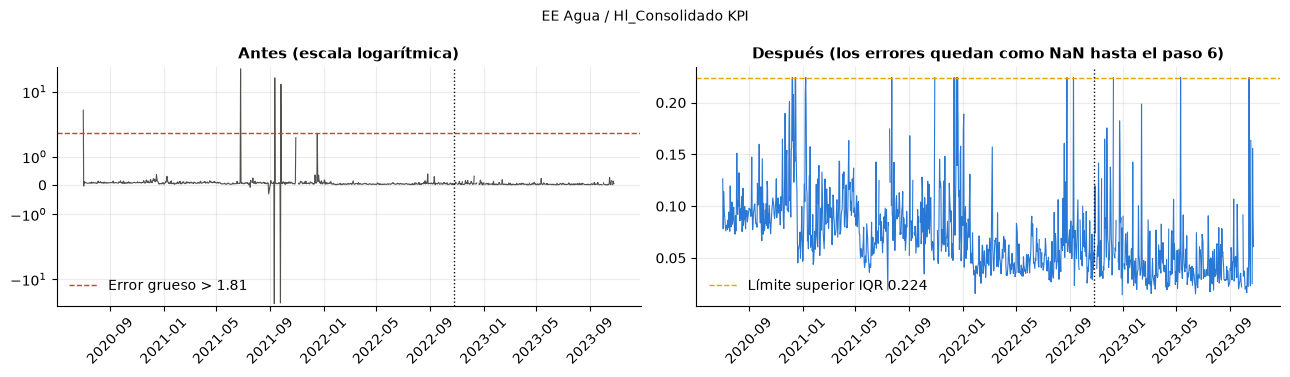

In [16]:
# Ejemplo: la columna con más errores gruesos, antes y después del tratamiento.
col = rep5.sort_values("n_errores_train", ascending=False)["columna"].iloc[0]
lim = paso5.limites_[col]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].plot(X4.index, X4[col], color="#52514e", lw=0.8)
axes[0].axhline(lim["tope"], color="#d03b3b", ls="--", lw=1, label=f"Error grueso > {lim['tope']:,.3g}")
axes[0].set_yscale("symlog")
axes[0].set_title("Antes (escala logarítmica)")
axes[0].legend(frameon=False)
axes[1].plot(X5.index, X5[col], color=SERIE[0], lw=0.8)
axes[1].axhline(lim["sup"], color="#eda100", ls="--", lw=1, label=f"Límite superior IQR {lim['sup']:,.3g}")
axes[1].set_title("Después (los errores quedan como NaN hasta el paso 6)")
axes[1].legend(frameon=False)
for ax in axes:
    ax.axvline(fin_train, color="#0b0b0b", lw=1, ls=":")
    # Rotar las etiquetas del eje X a 45 grados
    ax.tick_params(axis='x', labelrotation=45) 
fig.suptitle(col, fontsize=10)
plt.tight_layout()
plt.show()

## 8. Paso 5: imputación con búsqueda del mejor método

Para cada columna se elige el método con **menor error simulado en Train**:

1. Se ocultan valores observados de Train imitando los nulos reales de esa columna: rachas del mismo largo (10 %, mínimo 30 valores) y, si la columna empieza tarde, un bloque al comienzo de la serie. En ese bloque los métodos que miran días previos no tienen historia, igual que en el primer año real de las metas.
2. Se completan con cada método candidato y se mide **MAE / IQR**, que es comparable entre columnas de distinta escala.
3. Gana el menor error. Ante un empate, gana el método más simple.

Todos los candidatos son causales (usan solo días anteriores o estadísticos de Train): `mediana_train`, `ffill_3` (arrastre de hasta 3 días calendario), `mediana_dia_semana`, `mediana_mes` (mediana del mismo mes calendario en Train, pensada para las metas mensuales), `media_movil_7` (media de los 7 días previos) y `lag_7` (mismo día de la semana anterior). La interpolación lineal o el relleno hacia atrás usarían el futuro y quedan excluidos.

Los KPI indefinidos por falta de producción se completan con **0**: la columna de producción ya indica que ese día no se produjo. Las columnas con más de 5 % de nulos efectivos reciben un indicador `<col>__imputado`. Las que faltan exactamente los mismos días (por ejemplo, todas las metas) comparten **un único** indicador.

In [17]:
X6 = ajustar("imputar_nulos", ImputarNulos(cfg), X5)
paso6 = pasos_ajustados[-1][1]
rep6, busqueda = paso6.reporte_, paso6.tablas_["busqueda_imputacion"]

resumen_metodos = (busqueda.groupby("metodo")["mae_relativo"].median().rename("MAE/IQR mediano")
                   .to_frame().join(rep6["metodo_elegido"].value_counts().rename("veces elegido"))
                   .fillna(0).sort_values("MAE/IQR mediano"))
display(resumen_metodos)

ganancia = (1 - rep6["mae_relativo_elegido"] / rep6["mae_relativo_mediana"]).dropna()
print(f"Reducción mediana del error frente a imputar siempre con la mediana: {ganancia.median():.0%}")
print(f"Nulos que quedan: {int(X6.isna().sum().sum())} | indicadores agregados: {paso6.con_indicador_}")

imputar_nulos: 267 -> 269 columnas


,MAE/IQR mediano,veces elegido
metodo,,
ffill_3,0.483352,71
media_movil_7,0.494836,44
mediana_mes,0.532169,43
lag_7,0.548547,22
mediana_dia_semana,0.570784,24
mediana_train,0.582246,63


Reducción mediana del error frente a imputar siempre con la mediana: 22%
Nulos que quedan: 0 | indicadores agregados: ['Meta EE Planta_Consolidado KPI', 'Tot  Trasiego_Totalizadores Glicol']


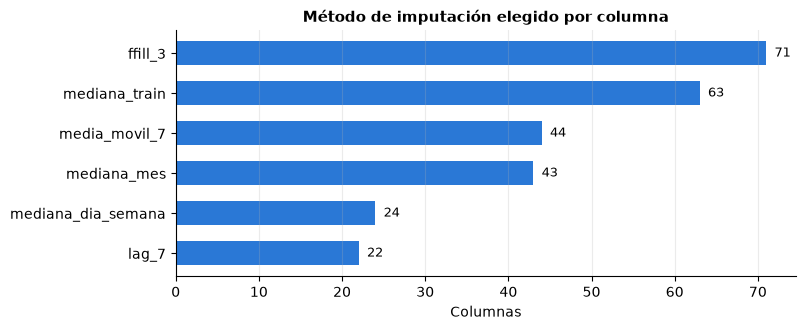

In [18]:
fig, ax = plt.subplots(figsize=(8, 3.2))
orden = resumen_metodos.sort_values("veces elegido")
ax.barh(orden.index, orden["veces elegido"], color=SERIE[0], height=0.6)
for i, v in enumerate(orden["veces elegido"]):
    ax.text(v + 1, i, f"{int(v)}", va="center", fontsize=9)
ax.set_title("Método de imputación elegido por columna")
ax.set_xlabel("Columnas")
ax.grid(axis="y", alpha=0)
plt.show()

In [19]:
# Detalle de las columnas con más nulos efectivos.
display(rep6.sort_values("pct_nulos_efectivos", ascending=False)
        [["columna", "pct_nulos_efectivos", "completados_con_cero_sin_produccion",
          "metodo_elegido", "mae_relativo_elegido", "mae_relativo_mediana", "agrega_indicador"]].head(10))

,columna,pct_nulos_efectivos,completados_con_cero_sin_produccion,metodo_elegido,mae_relativo_elegido,mae_relativo_mediana,agrega_indicador
65,Meta Agua Servicios_Consolidado KPI,0.434676,0,mediana_train,0.223701,0.223701,True
66,Meta Agua Planta de Agua_Consolidado KPI,0.434676,0,mediana_train,0.223701,0.223701,True
54,Meta EE Planta_Consolidado KPI,0.434676,0,mediana_train,0.593692,0.593692,True
61,Meta Agua Envas_Consolidado KPI,0.434676,0,mediana_train,0.223701,0.223701,True
62,Meta Agua Linea 2_Consolidado KPI,0.434676,0,mediana_train,0.223701,0.223701,True
60,Meta Agua Cocina_Consolidado KPI,0.434676,0,mediana_train,0.223701,0.223701,True
63,Meta Agua Linea 4_Consolidado KPI,0.434676,0,mediana_train,0.223701,0.223701,True
69,Meta EE Cocina_Consolidado KPI,0.434676,0,mediana_train,0.593692,0.593692,True
68,Meta EE Bodega_Consolidado KPI,0.434676,0,mediana_train,0.593692,0.593692,True
70,Meta EE Envasado_Consolidado KPI,0.434676,0,mediana_train,0.593692,0.593692,True


In [20]:
metas6 = rep6[rep6["columna"].str.startswith("Meta ")]
resumen_metas = metas6.groupby("metodo_elegido")["columna"].agg(
    metas="count", ejemplos=lambda s: ", ".join(s.str.split("_").str[0].head(4)))
display(resumen_metas)

,metas,ejemplos
metodo_elegido,,
mediana_mes,10,"Meta ET Planta, Meta ET Elab, Meta ET Bodega, Meta ET Cocina"
mediana_train,33,"Meta EE Planta, Meta Agua Planta, Meta Aire Planta, Meta Agua Elab"


Que los métodos temporales (`ffill_3`, `media_movil_7`) ganen en la mayoría de las columnas confirma lo esperable en una serie diaria: el valor de ayer predice mejor que la mediana de todo Train.

En las metas, la mediana del mismo mes solo mejora a la mediana global en las de **energía térmica** (`Meta ET`), que tienen estacionalidad. Las metas de energía eléctrica cambian sobre todo con la revisión anual de julio, no con la estación, así que el mes no ayuda a reconstruir el primer año.

## 9. Verificación de causalidad e impacto por partición

**Causalidad.** Si transformar la historia hasta una fecha da exactamente lo mismo que transformar toda la serie y recortar en esa fecha, ningún paso usa información futura. Se prueba en el fin de Train, en el fin de Validation y dentro de Test.

**Impacto.** Cuántos valores modificó cada paso en cada partición. Si un tratamiento modifica mucho más Validation o Test que Train, los límites de Train no representan bien el período nuevo.

In [21]:
pipeline = Pipeline(pasos_ajustados)
causalidad = pp.verificar_causalidad(
    pipeline, X, [fin_train, cortes["validation"][1], cortes["test"][0] + pd.Timedelta(days=30)])
display(causalidad)
assert causalidad["causal"].all(), "Algún paso usa información futura"

X_proc = X6
impacto = pp.impacto_por_paso(pipeline, X, particion)
tabla_impacto = impacto.pivot(index="paso", columns="particion", values="pct_valores").mul(100).round(2)
display(tabla_impacto.loc[[n for n, _ in pasos_ajustados], ["train", "validation", "test", "sin_etiqueta"]]
        .rename(columns=lambda c: f"% {c}"))

,corte,filas,max_diferencia,causal
0,2022-10-26,819,0.0,True
1,2023-04-29,997,0.0,True
2,2023-05-30,1028,0.0,True


particion,% train,% validation,% test,% sin_etiqueta
paso,,,,
aplicar_decisiones_eda,0.27,0.00,0.00,0.19
descartar_no_informativas,0.00,0.00,0.00,0.00
descartar_duplicadas,0.00,0.00,0.00,0.00
filtrar_por_nulos,0.00,0.00,0.00,0.00
outliers_univariados,1.09,1.70,1.44,1.40
imputar_nulos,8.27,3.34,2.39,6.58


In [22]:
display(impacto[impacto["paso"] == "outliers_univariados"][["particion", "valores_modificados", "top_columnas"]])

,particion,valores_modificados,top_columnas
16,sin_etiqueta,120,Totalizador Bba P51_Totalizadores Efluentes (8); CO 2 Linea 4 / Hl_Consolidado KPI (7)...
17,test,656,CO 2 Linea 4 / Hl_Consolidado KPI (110); Totalizador_L2_Barriles_Totalizadores CO2 (44...
18,train,2314,TOT AGUA DESAIREADA_Totalizadores Gas y Vapor (154); Agua Enjuagadora L2_Totalizadores...
19,validation,774,Totalizador Bba P51_Totalizadores Efluentes (86); CO 2 Linea 4 / Hl_Consolidado KPI (7...


## 10. Análisis multivariado con LOF

Local Outlier Factor detecta días que son raros por la **combinación** de valores, aunque cada variable por separado esté en rango. Este paso no modifica los datos: marca días.

* Estandarización y PCA (90 % de varianza) ajustados en Train. Se usa `StandardScaler` y no `RobustScaler` porque las columnas con casi todos ceros tienen IQR ≈ 0, y el escalado robusto las amplifica a valores z de miles, lo que degenera el LOF. Los extremos ya fueron winsorizados.
* **Búsqueda de `n_neighbors`:** se prueba una grilla y se elige el valor cuyo conjunto de días anómalos es más estable (mayor Jaccard medio con el resto).
* Train se puntúa con el ajuste. Validation y Test se puntúan con `novelty=True`, es decir, comparados contra Train sin reajustar.
* Un día se marca como anómalo si su LOF es mayor a 1,5.

In [23]:
lof = AnalisisLOF(cfg).fit(X_proc.loc[:fin_train])
anomalias = lof.puntuar(X_proc).assign(particion=particion)
display(lof.sensibilidad_)
print(f"n_neighbors elegido: {lof.k_} | componentes PCA: {lof.pca_.n_components_}")
display(anomalias.groupby("particion")["anomalo_lof"].agg(["sum", "count", "mean"])
        .rename(columns={"sum": "anómalos", "count": "días", "mean": "proporción"}))

,n_neighbors,dias_anomalos_train,jaccard_medio
0,10,18,0.615649
1,20,14,0.692982
2,35,17,0.715488
3,50,16,0.630181


n_neighbors elegido: 35 | componentes PCA: 57


,anómalos,días,proporción
particion,,,
sin_etiqueta,9,32,0.281250
test,119,171,0.695906
train,15,798,0.018797
validation,80,171,0.467836


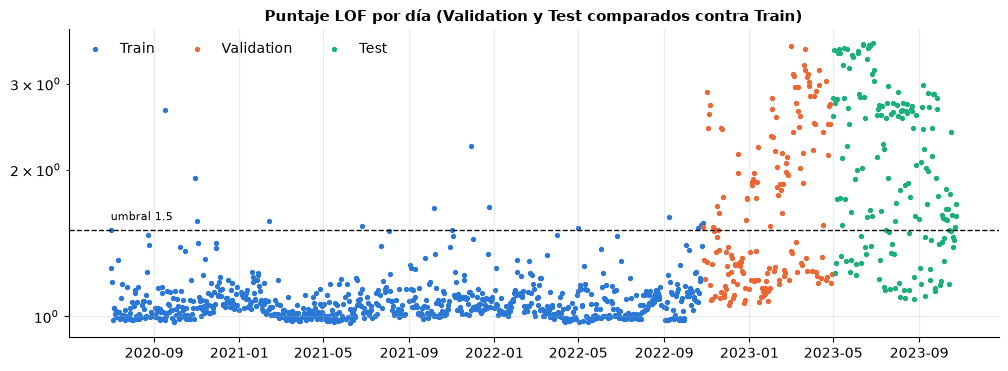

In [24]:
fig, ax = plt.subplots()
for nombre in ("train", "validation", "test"):
    parte = anomalias[anomalias["particion"] == nombre]
    ax.scatter(parte.index, parte["lof_score"], s=8, color=COLORES[nombre], label=nombre.capitalize())
ax.axhline(cfg.lof_umbral, color="#0b0b0b", ls="--", lw=1)
ax.text(X.index.min(), cfg.lof_umbral * 1.05, f"umbral {cfg.lof_umbral}", fontsize=8)
ax.set_yscale("log")
ax.set_title("Puntaje LOF por día (Validation y Test comparados contra Train)")
ax.legend(frameon=False, ncol=3)
plt.show()

In [25]:
# ¿Qué variables explican los días anómalos de cada partición?
for nombre in ("train", "validation", "test"):
    marcados = anomalias[(anomalias["particion"] == nombre) & anomalias["anomalo_lof"]]
    top = marcados["variables_mas_atipicas"].str.split(", ").explode().value_counts().head(5)
    print(f"\n{nombre.upper()} ({len(marcados)} días anómalos):")
    print(top.to_string())


TRAIN (15 días anómalos):
variables_mas_atipicas
Agua Red Servicios_Totalizadores Agua      4
Produccion Agua / Hl_Consolidado KPI       3
Agua Planta de Agua/Hl_Consolidado KPI     3
KW Iluminacion L3_Totalizadores Energia    2
KW Iluminacion L4_Totalizadores Energia    2

VALIDATION (80 días anómalos):
variables_mas_atipicas
Totalizador_L2_Barriles_Totalizadores CO2               79
KW Trafo 12_Totalizadores Energia                       42
CAUDAL DE GAS CALDERA 1 M3_Totalizadores Gas y Vapor    28
Agua Red Servicios_Totalizadores Agua                   23
Agua Cond REC_Totalizadores Agua                        18

TEST (119 días anómalos):
variables_mas_atipicas
Totalizador_L2_Barriles_Totalizadores CO2     118
KW Secador Kaeser_Totalizadores Energia        98
Totalizador_Aire_Bodega_Totalizadores Aire     38
Red  Bodega Interno_Totalizadores Agua         33
KW Trafo 12_Totalizadores Energia              26


**Lectura.** En Train el LOF marca pocos días (15 de 798, 1,9 %). En Validation marca 80 de 171 (47 %) y en Test 119 de 171 (70 %).

Sin los compresores, que la EDA excluyó, las variables responsables son otras, pero el patrón se mantiene: casi todos los días anómalos de Validation y de Test lo son por la línea de barriles L2 (`Totalizador_L2_Barriles`), casi inactiva en Train. Le siguen el transformador 12, el gas de la caldera 1 y, en Test, el secador Kaeser. No son errores de medición sino **cambios de operación posteriores a Train**: equipos que empiezan a funcionar o cambian de carga. Que la proporción no baje al quitar los compresores muestra que el cambio de régimen no se limita al sistema de frío.

Por eso la decisión por defecto es `tratamiento_lof="reportar"`: eliminar días de Validation o Test nunca es válido, y en Train hay pocos marcados. La alternativa `"excluir_train"` está disponible para compararla en el modelado.

## 11. Producción del mismo día y consumo de frío

La consigna sugiere que el frío depende del volumen de producción y de la etapa de fermentación. Medimos esa relación **solo en Train** y con tres preguntas:

1. **Directa:** Spearman de cada volumen de producción del día D con el frío de D y con `y` (frío de D+1).
2. **Sin la estación:** en verano se produce más cerveza y también hace más calor, así que parte de la correlación puede venir de la estación. Repetimos la medición sobre los residuos (en rangos) de regresar cada variable contra la temperatura media de 7 días de Open-Meteo.
3. **Además de la persistencia:** el frío de hoy y su media de 7 días ya predicen bien a `y`. Medimos la correlación de la producción con lo que esas dos **no** explican. Esta es la pregunta que importa para el modelo.

In [26]:
clima = pd.read_csv(raiz / "data" / "reference" / "clima_tecate_openmeteo.csv",
                    parse_dates=["DIA"]).set_index("DIA")
tr = X.loc[:fin_train]
y_tr = y.reindex(tr.index)
frio_tr = tr[pp.COL_FRIO]
temp7 = clima["temp_media_c"].rolling(7, min_periods=1).mean().reindex(tr.index)

def residuo(serie, controles):
    # Residuo de una regresión lineal (ajustada en Train) de `serie` sobre `controles`.
    ok = serie.notna() & controles.notna().all(axis=1)
    A = np.c_[np.ones(ok.sum()), controles[ok].to_numpy()]
    coef = np.linalg.lstsq(A, serie[ok].to_numpy(), rcond=None)[0]
    res = pd.Series(np.nan, index=serie.index)
    res[ok] = serie[ok] - A @ coef
    return res

control_temp = temp7.to_frame("temp7")
y_sin_temp = residuo(y_tr.rank(), control_temp)
frio_sin_temp = residuo(frio_tr.rank(), control_temp)
persistencia = pd.DataFrame({"frio_D": frio_tr,
                             "frio_media7": frio_tr.asfreq("D").rolling(7, min_periods=4).mean().reindex(tr.index)})
y_no_explicado = residuo(y_tr, persistencia)

produccion = ["Hl de Mosto", "Hl Cerveza Cocina", "Hl Producido Bodega", "Hl Cerveza Filtrada",
              "Hl Cerveza Envasada", "Hl Cerveza L2", "Hl Cerveza L3", "Hl Cerveza L4",
              "Hl Cerveza L5", "Cocimientos Diarios"]
filas = []
for nombre in produccion:
    s = tr[f"{nombre}_Consolidado Produccion"]
    s_sin_temp = residuo(s.rank(), control_temp)
    filas.append({
        "variable": nombre,
        "frío D": s.corr(frio_tr, method="spearman"),
        "y (D+1)": s.corr(y_tr, method="spearman"),
        "frío D sin temperatura": s_sin_temp.corr(frio_sin_temp),
        "y sin temperatura": s_sin_temp.corr(y_sin_temp),
        "y no explicado por persistencia": s.corr(y_no_explicado, method="spearman"),
        "% días en 0": (s == 0).mean() * 100,
    })
tabla_prod = pd.DataFrame(filas).set_index("variable")
print(f"Temperatura (media 7 días) vs frío D: {temp7.corr(frio_tr, method='spearman'):.2f} | "
      f"vs y: {temp7.corr(y_tr, method='spearman'):.2f}")
display(tabla_prod.round(2))

Temperatura (media 7 días) vs frío D: 0.54 | vs y: 0.53


,frío D,y (D+1),frío D sin temperatura,y sin temperatura,y no explicado por persistencia,% días en 0
variable,,,,,,
Hl de Mosto,0.40,0.33,0.45,0.38,0.03,8.18
Hl Cerveza Cocina,0.39,0.34,0.43,0.38,0.05,8.18
Hl Producido Bodega,0.58,0.52,0.62,0.54,0.11,1.10
Hl Cerveza Filtrada,0.54,0.42,0.54,0.40,-0.05,2.69
Hl Cerveza Envasada,0.50,0.47,0.50,0.45,0.13,3.05
Hl Cerveza L2,0.30,0.25,0.31,0.25,0.06,15.87
Hl Cerveza L3,0.30,0.29,0.31,0.30,0.14,21.73
Hl Cerveza L4,0.29,0.25,0.31,0.27,0.01,10.74
Hl Cerveza L5,0.32,0.27,0.30,0.24,0.06,58.00


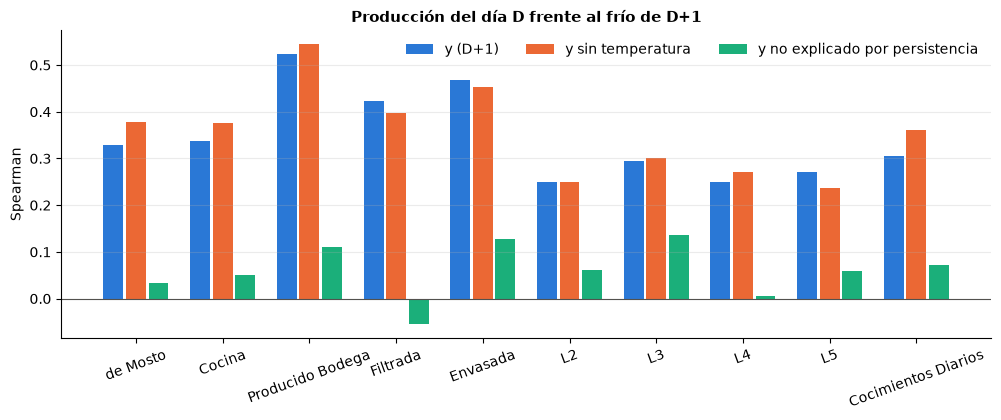

In [27]:
fig, ax = plt.subplots(figsize=(12, 4))
cols = ["y (D+1)", "y sin temperatura", "y no explicado por persistencia"]
ancho = 0.26
pos = np.arange(len(tabla_prod))
for i, col in enumerate(cols):
    ax.bar(pos + (i - 1) * ancho, tabla_prod[col], width=ancho - 0.03, color=SERIE[i], label=col)
ax.axhline(0, color="#52514e", lw=0.8)
ax.set_xticks(pos, [v.replace("Hl ", "").replace("Cerveza ", "") for v in tabla_prod.index], rotation=20)
ax.set_ylabel("Spearman")
ax.set_title("Producción del día D frente al frío de D+1")
ax.legend(frameon=False, ncol=3, loc="upper right")
ax.grid(axis="x", alpha=0)
plt.show()

**Rezagos y acumulados.** La cerveza que entra a fermentar hoy necesita frío durante varios días. Si eso se refleja en el consumo, el volumen producido días atrás, o acumulado en una ventana, debería relacionarse con `y` incluso más que el del mismo día. Todas las ventanas usan solo días ≤ D.

In [28]:
rezagos = [0, 1, 2, 3, 5, 7, 10, 14]
filas = {}
for nombre in ["Hl de Mosto", "Hl Producido Bodega", "Hl Cerveza Filtrada", "Hl Cerveza Envasada"]:
    s = tr[f"{nombre}_Consolidado Produccion"].asfreq("D")
    fila = {f"D-{k}": residuo(s.shift(k).reindex(tr.index).rank(), control_temp).corr(y_sin_temp)
            for k in rezagos}
    for v in (7, 14):
        acumulado = s.rolling(v, min_periods=v // 2).sum().reindex(tr.index)
        fila[f"suma {v} días"] = residuo(acumulado.rank(), control_temp).corr(y_sin_temp)
        fila[f"suma {v} días, además de persistencia"] = acumulado.corr(y_no_explicado, method="spearman")
    filas[nombre] = fila
print("Spearman con y, sin el efecto de la temperatura (Train):")
display(pd.DataFrame(filas).T.round(2))

Spearman con y, sin el efecto de la temperatura (Train):


,D-0,D-1,D-2,D-3,D-5,D-7,D-10,D-14,suma 7 días,"suma 7 días, además de persistencia",suma 14 días,"suma 14 días, además de persistencia"
Hl de Mosto,0.38,0.32,0.30,0.29,0.28,0.34,0.34,0.25,0.51,-0.00,0.60,0.05
Hl Producido Bodega,0.54,0.42,0.37,0.37,0.43,0.48,0.45,0.42,0.55,0.02,0.61,0.06
Hl Cerveza Filtrada,0.40,0.33,0.35,0.36,0.42,0.36,0.37,0.36,0.57,0.04,0.61,0.07
Hl Cerveza Envasada,0.45,0.32,0.28,0.27,0.38,0.38,0.33,0.36,0.54,0.05,0.58,0.07


In [29]:
perfil = pd.DataFrame({
    "Frío": tr[pp.COL_FRIO],
    "Hl Bodega": tr["Hl Producido Bodega_Consolidado Produccion"],
    "Hl Envasada": tr["Hl Cerveza Envasada_Consolidado Produccion"],
    "Hl Mosto": tr["Hl de Mosto_Consolidado Produccion"],
}).groupby(tr.index.day_of_week).median()
perfil = (perfil / perfil.mean()).rename(index=dict(enumerate(["lun", "mar", "mié", "jue", "vie", "sáb", "dom"])))
print("Mediana por día de la semana, relativa al promedio semanal (Train):")
display(perfil.T.round(2))

Mediana por día de la semana, relativa al promedio semanal (Train):


DIA,lun,mar,mié,jue,vie,sáb,dom
Frío,0.99,1.02,1.05,1.03,0.97,0.95,1.00
Hl Bodega,0.97,1.06,1.09,0.94,0.94,0.99,1.00
Hl Envasada,0.91,1.13,1.18,1.04,0.92,1.02,0.81
Hl Mosto,1.05,0.99,0.96,0.96,0.98,1.02,1.04


**Lectura:**

* La producción del mismo día se relaciona con el frío. **Hl Producido Bodega** es la más fuerte (Spearman 0,52 con `y`), y la relación **no se explica por la temperatura**: al quitarla, la correlación se mantiene o sube un poco (0,54).
* Los **acumulados de 14 días** se relacionan más que el valor del día (alrededor de 0,6 frente a 0,4–0,5), lo que es coherente con la fermentación: la cerveza producida en las últimas dos semanas sigue en tanques que se enfrían.
* Pero casi toda esa información **ya está en la historia del frío**. Respecto de lo que no explican el frío de hoy y su media de 7 días, la correlación cae a entre −0,05 y 0,14. Los aportes más altos son los de **L3, Envasada y Bodega del día D** (0,14, 0,13 y 0,11); los acumulados de 7 y 14 días aportan menos que el valor del día (≤ 0,07).
* El efecto del día de la semana es chico en el frío (±5 %) y mayor en envasado (±18 %).

**Consecuencia para la selección:** la producción entra como candidata, sobre todo Bodega, Envasada y L3 del día D, pero hay que esperar un aporte marginal sobre los rezagos y medias móviles del frío. Los acumulados de 14 días de producción son candidatos redundantes con la media móvil del frío.

## 12. Hipótesis: las metas dependen de la temperatura y de la producción

**Hipótesis del grupo:** las metas de consumo por hectolitro se fijan según la temperatura esperada en ese período y según el volumen de cerveza a producir. Si es así, las metas resumen información que se conoce de antemano y podrían ayudar al modelo.

Las metas son **mensuales** (valen lo mismo todo el mes), así que la comparación se hace por mes. En Train hay 16 meses con metas (julio de 2021 a octubre de 2022). Con 16 puntos cualquier correlación es incierta, por eso se reporta el p-valor.

In [30]:
from scipy.stats import spearmanr

metas = [c for c in tr.columns if c.startswith("Meta ")]
mes = tr.index.to_period("M")
constantes = (tr[metas].groupby(mes).nunique() <= 1).to_numpy().mean()
print(f"Proporción de pares meta-mes con un único valor: {constantes:.0%}")

mensual = (tr[metas].groupby(mes).median()
           .join(clima["temp_media_c"].groupby(clima.index.to_period("M")).mean().rename("temperatura mes"))
           .join(tr[["Hl Producido Bodega_Consolidado Produccion", "Hl Cerveza Envasada_Consolidado Produccion",
                     pp.COL_FRIO]].groupby(mes).sum())
           .dropna(subset=["Meta EE Frio_Consolidado KPI"]))
mensual.columns = [c.split("_")[0] for c in mensual.columns]
print(f"Meses de Train con metas: {len(mensual)} ({mensual.index.min()} a {mensual.index.max()})")

filas = []
for meta in ["Meta EE Frio", "Meta EE Planta", "Meta ET Planta", "Meta Agua Planta"]:
    for contra in ["temperatura mes", "Hl Producido Bodega", "Hl Cerveza Envasada", "Frio (Kw)"]:
        rho, p = spearmanr(mensual[meta], mensual[contra])
        filas.append({"meta": meta, "contra": contra, "rho": rho, "p_valor": p})
tabla_metas = pd.DataFrame(filas).pivot(index="meta", columns="contra", values=["rho", "p_valor"]).round(3)
display(tabla_metas)

Proporción de pares meta-mes con un único valor: 100%
Meses de Train con metas: 16 (2021-07 a 2022-10)


rho                                                           p_valor                                                        
contra           Frio (Kw) Hl Cerveza Envasada Hl Producido Bodega temperatura mes Frio (Kw) Hl Cerveza Envasada Hl Producido Bodega temperatura mes
meta                                                                                                                                                
Meta Agua Planta    -0.298              -0.490              -0.584           0.073     0.262               0.054               0.018           0.788
Meta EE Frio        -0.181              -0.512              -0.653           0.419     0.501               0.043               0.006           0.106
Meta EE Planta      -0.181              -0.512              -0.653           0.419     0.501               0.043               0.006           0.106
Meta ET Planta      -0.815              -0.474              -0.368          -0.730     0.000               0.064               0.161           0.001

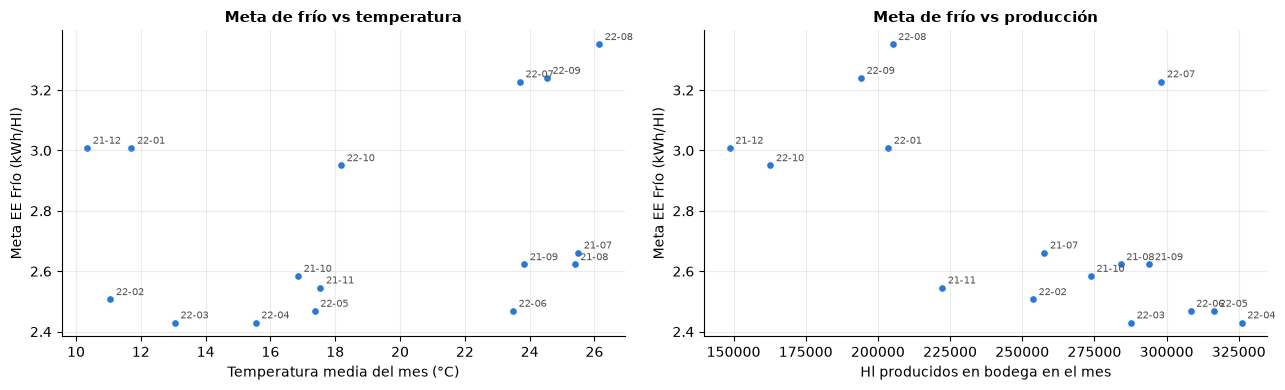

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, contra, etiqueta in [(axes[0], "temperatura mes", "Temperatura media del mes (°C)"),
                             (axes[1], "Hl Producido Bodega", "Hl producidos en bodega en el mes")]:
    ax.scatter(mensual[contra], mensual["Meta EE Frio"], s=40, color=SERIE[0],
               edgecolor="#fcfcfb", linewidth=1.5)
    for periodo, fila in mensual.iterrows():
        ax.annotate(periodo.strftime("%y-%m"), (fila[contra], fila["Meta EE Frio"]),
                    fontsize=7, xytext=(4, 3), textcoords="offset points", color="#52514e")
    ax.set_xlabel(etiqueta)
    ax.set_ylabel("Meta EE Frío (kWh/Hl)")
axes[0].set_title("Meta de frío vs temperatura")
axes[1].set_title("Meta de frío vs producción")
plt.tight_layout()
plt.show()

In [32]:
# ¿La meta aporta información diaria? Frío "esperado" según la meta: Meta EE Frío × Hl de bodega del día.
esperado = tr["Meta EE Frio_Consolidado KPI"] * tr["Hl Producido Bodega_Consolidado Produccion"]
print(f"Frío esperado por la meta vs frío D: {esperado.corr(frio_tr, method='spearman'):.2f}")
print(f"Frío esperado por la meta vs y: {esperado.corr(y_tr, method='spearman'):.2f}")
print(f"Frío esperado por la meta vs y no explicado por persistencia: "
      f"{esperado.corr(y_no_explicado, method='spearman'):.2f}")

Frío esperado por la meta vs frío D: 0.59
Frío esperado por la meta vs y: 0.49
Frío esperado por la meta vs y no explicado por persistencia: 0.05


**Lectura:**

* **Producción: la hipótesis se sostiene.** Las metas de energía por hectolitro son **más altas en los meses de menor producción** (Meta EE Frío vs Hl de bodega: Spearman −0,65). Tiene sentido físico: buena parte del frío es carga fija (mantener tanques y cámaras), que se reparte entre menos hectolitros cuando se produce poco.
* **Temperatura: la evidencia es parcial.** La meta de frío sube con la temperatura (+0,42), pero con 16 meses el p-valor no permite afirmarlo. La meta de energía térmica (`Meta ET Planta`) sí sigue claramente a la estación, al revés (−0,73): se calienta más en invierno.
* **Las metas cambian por revisión anual.** El salto de julio de 2022 (de 2,47 a 3,23 kWh/Hl) coincide con el inicio de un nuevo ciclo de planificación, no con un cambio de temperatura ni de producción. Una parte importante de su variación es presupuestaria.
* **Aporte al pronóstico diario.** El frío "esperado" por la meta (meta × Hl de bodega) se relaciona con el frío (0,59 con el de hoy), pero frente a lo que no explica la persistencia su correlación es 0,05.

**Consecuencia para la selección:** las metas se conservan como candidatas, porque se conocen de antemano, pero lo esperable es que aporten poco por encima de los rezagos del frío. La selección lo decide con datos.

## 13. Ciclo anual, regímenes e interacciones: evidencia para crear variables

Las secciones 11 y 12 miraron cada predictora por separado. Antes de la selección conviene preguntar si hay estructura que ninguna columna representa por sí sola, porque eso justifica **crear** variables. Tres preguntas, todas con datos de Train:

1. **Ciclo anual.** ¿El calendario reproduce la estacionalidad de la temperatura y del frío? Si es así, el seno y el coseno del día del año resumen la estación con un valor que se conoce de antemano y que no depende de una fuente meteorológica externa (decisión todavía pendiente).
2. **Regímenes (binning).** ¿La relación entre el frío de hoy y el de mañana es la misma en todo el rango? ¿Los días sin producción forman un grupo aparte?
3. **Interacciones.** ¿El efecto del frío de hoy y de la producción sobre `y` cambia con la estación?

Las variables se construyen en `src/seleccion_variables.py`, que arma las candidatas. Acá se usa la misma función (`variables_ciclo_anual`) para que el análisis y las variables coincidan.

In [33]:
from src.seleccion_variables import variables_ciclo_anual

def ajuste_anual(serie, armonicos):
    # Regresión de la serie sobre 1 + seno y coseno anuales (armónicos dados), solo días con dato.
    A = np.c_[np.ones(len(serie)), variables_ciclo_anual(serie.index, armonicos).to_numpy()]
    ok = serie.notna().to_numpy()
    coef = np.linalg.lstsq(A[ok], serie.to_numpy()[ok], rcond=None)[0]
    curva = pd.Series(A @ coef, index=serie.index)
    r2 = 1 - (serie - curva)[ok].var() / serie[ok].var()
    # La misma curva sobre un año de referencia (no bisiesto) para ubicar el pico.
    anio = pd.date_range("2021-01-01", "2021-12-31")
    A_ref = np.c_[np.ones(len(anio)), variables_ciclo_anual(anio, armonicos).to_numpy()]
    return r2, curva, pd.Series(A_ref @ coef, index=anio)

def r2_doce_meses(serie):
    # R² de explicar la serie con la media de cada mes (equivale a 11 indicadores de mes).
    ok = serie.dropna()
    return 1 - (ok - ok.groupby(ok.index.month).transform("mean")).var() / ok.var()

series_anuales = {
    "Temperatura diaria": clima["temp_media_c"].reindex(tr.index),
    "Temperatura (media 7 días)": temp7,
    "Hl Producido Bodega": tr["Hl Producido Bodega_Consolidado Produccion"],
    "Frío D": frio_tr,
    "y (frío D+1)": y_tr,
}
filas, curvas_ref = [], {}
for nombre, s in series_anuales.items():
    r2_1, _, _ = ajuste_anual(s, (1,))
    r2_2, _, ref = ajuste_anual(s, (1, 2))
    curvas_ref[nombre] = ref
    filas.append({"serie": nombre, "R² armónico 1 (2 col.)": r2_1, "R² armónicos 1 y 2 (4 col.)": r2_2,
                  "R² 12 meses (11 col.)": r2_doce_meses(s), "pico del ciclo": ref.idxmax().strftime("%d-%m")})
tabla_ciclo = pd.DataFrame(filas).set_index("serie")
display(tabla_ciclo.round(3))

,R² armónico 1 (2 col.),R² armónicos 1 y 2 (4 col.),R² 12 meses (11 col.),pico del ciclo
serie,,,,
Temperatura diaria,0.723,0.737,0.732,11-08
Temperatura (media 7 días),0.828,0.844,0.831,14-08
Hl Producido Bodega,0.190,0.236,0.277,22-04
Frío D,0.635,0.668,0.680,04-06
y (frío D+1),0.640,0.672,0.680,03-06


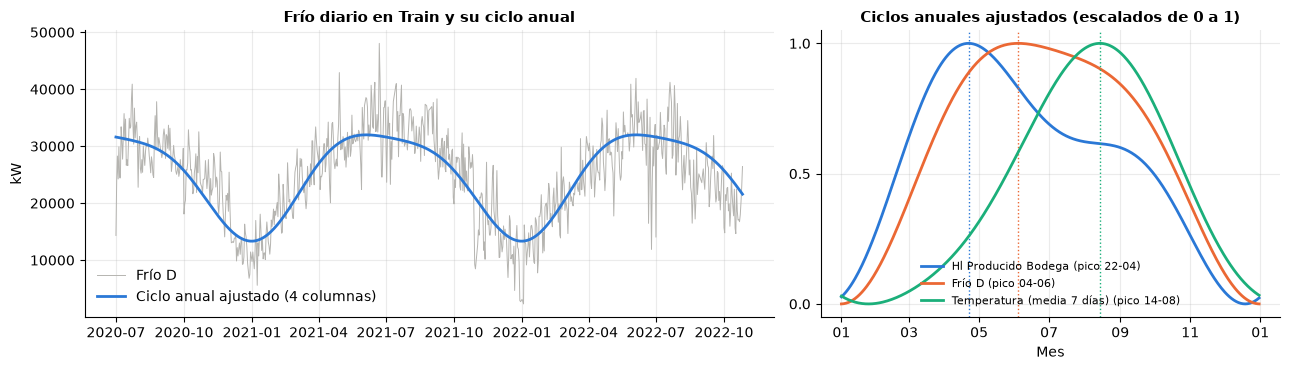

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1.5, 1]})
_, curva_frio, _ = ajuste_anual(frio_tr, (1, 2))
axes[0].plot(tr.index, frio_tr, color="#b5b4b0", lw=0.7, label="Frío D")
axes[0].plot(tr.index, curva_frio, color=SERIE[0], lw=2, label="Ciclo anual ajustado (4 columnas)")
axes[0].set_title("Frío diario en Train y su ciclo anual")
axes[0].set_ylabel("kW")
axes[0].legend(frameon=False, loc="lower left")

for i, nombre in enumerate(["Hl Producido Bodega", "Frío D", "Temperatura (media 7 días)"]):
    ref = curvas_ref[nombre]
    escalada = (ref - ref.min()) / (ref.max() - ref.min())
    axes[1].plot(escalada.index, escalada, color=SERIE[i], lw=2, label=f"{nombre} (pico {ref.idxmax():%d-%m})")
    axes[1].axvline(ref.idxmax(), color=SERIE[i], lw=1, ls=":")
axes[1].xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%m"))
axes[1].set_xlabel("Mes")
axes[1].set_title("Ciclos anuales ajustados (escalados de 0 a 1)")
axes[1].set_yticks([0, 0.5, 1])
axes[1].legend(frameon=False, fontsize=8, loc="lower center")
plt.tight_layout()
plt.show()

In [35]:
# 13.2 Regímenes: cambio del frío de hoy a mañana según el nivel del frío de hoy (quintiles de Train).
quintil_frio = pd.qcut(frio_tr, 5)
regimen = pd.DataFrame({
    "días": quintil_frio.value_counts(sort=False),
    "y − frío D (mediana)": (y_tr - frio_tr).groupby(quintil_frio, observed=True).median(),
    "residuo tras persistencia lineal (media)": y_no_explicado.groupby(quintil_frio, observed=True).mean(),
})
regimen.index = [f"Q{i} ({iv.left:,.0f} a {iv.right:,.0f})" for i, iv in enumerate(regimen.index, 1)]
print("Frío de D+1 según el quintil del frío de D (kW, Train):")
display(regimen.round(0))

print("Producción con días en cero en Train (tabla de la sección 11):")
display(tabla_prod[["% días en 0"]].sort_values("% días en 0", ascending=False).round(1).T)

Frío de D+1 según el quintil del frío de D (kW, Train):


,días,y − frío D (mediana),residuo tras persistencia lineal (media)
"Q1 (2,310 a 17,771)",164,209.0,-417.0
"Q2 (17,771 a 23,691)",164,796.0,434.0
"Q3 (23,691 a 27,721)",163,0.0,-53.0
"Q4 (27,721 a 31,673)",164,3.0,495.0
"Q5 (31,673 a 48,046)",164,-2494.0,-472.0


Producción con días en cero en Train (tabla de la sección 11):


variable,Hl Cerveza L5,Hl Cerveza L3,Hl Cerveza L2,Hl Cerveza L4,Hl Cerveza Cocina,Hl de Mosto,Cocimientos Diarios,Hl Cerveza Envasada,Hl Cerveza Filtrada,Hl Producido Bodega
% días en 0,58.0,21.7,15.9,10.7,8.2,8.2,5.0,3.1,2.7,1.1


In [36]:
# 13.3 ¿La persistencia y el aporte de la producción cambian con la estación?
# Mitad cálida = días con el ciclo anual del frío por encima de su mediana.
calido = curva_frio >= curva_frio.median()
filas = []
for nombre, mascara in [("mitad cálida", calido), ("mitad fría", ~calido)]:
    ok = mascara & y_tr.notna()
    pendiente = np.polyfit(frio_tr[ok], y_tr[ok], 1)[0]
    fila = {"estación": nombre, "días": int(ok.sum()), "pendiente de y sobre frío D": pendiente}
    for etiqueta, col in [("Bodega", "Hl Producido Bodega"), ("Envasada", "Hl Cerveza Envasada"),
                          ("Mosto", "Hl de Mosto")]:
        s = tr.loc[mascara, f"{col}_Consolidado Produccion"]
        fila[f"{etiqueta} vs y no explicado"] = s.corr(y_no_explicado[mascara], method="spearman")
    filas.append(fila)
display(pd.DataFrame(filas).set_index("estación").round(2))

,días,pendiente de y sobre frío D,Bodega vs y no explicado,Envasada vs y no explicado,Mosto vs y no explicado
estación,,,,,
mitad cálida,398,0.54,0.05,0.07,-0.01
mitad fría,400,0.82,0.13,0.14,0.04


**Lectura:**

* **Ciclo anual.** Dos columnas (seno y coseno del día del año) explican el 72 % de la varianza de la temperatura diaria de Train, el 83 % de su media de 7 días y el 64 % del frío. Con el segundo armónico (4 columnas) el frío llega a 67 %, casi lo mismo que los 12 meses (68 %, 11 columnas). El ciclo continuo resume la estación con menos columnas y sin saltos entre un mes y el siguiente.
* **Los picos no coinciden.** El ciclo ajustado de la producción de bodega tiene su máximo a fines de abril, el del frío a principios de junio y el de la temperatura a mediados de agosto. El frío queda entre los dos y se mantiene alto de junio a septiembre, coherente con que dependa de ambos. Por eso no conviene fijar de antemano una fase de "verano": con el seno y el coseno juntos, el modelo la elige. La estacionalidad de la producción es débil (el ciclo explica solo el 24 % de su varianza).
* **Regímenes.** El cambio de hoy a mañana depende del nivel: en el quintil más alto el frío de mañana baja una mediana de 2.494 kW, y en los dos más bajos sube. Una parte es reversión a la media lineal, pero aun después de descontar la persistencia lineal (frío D y su media de 7 días) el residuo alterna de signo entre quintiles (de −472 a +495 kW). Un término lineal no puede representar ese patrón; un indicador por quintil sí.
* **Ceros.** Mosto y Cocina tienen 8 % de días sin producción en Train (las líneas de envasado, más). Esos días son otro régimen (no hubo cocimiento), así que conviene que el cero sea un intervalo propio y no se mezcle con los valores bajos.
* **Interacciones.** La persistencia es más débil en la mitad cálida (pendiente 0,54 contra 0,82): en verano, después de un día de frío alto hay más reversión. Y la producción aporta además de la persistencia casi solo en la mitad fría (0,13 a 0,14 en bodega y envasado, frente a 0,05 a 0,07 en la cálida). El efecto del frío de hoy y el de la producción cambian con la estación.

**Consecuencia para la selección.** Se agregan tres familias de candidatas en `src/seleccion_variables.py`:

1. **Ciclo anual**: `anio_sin_k` y `anio_cos_k` para k = 1 y 2.
2. **Binning**: indicadores por cuantiles de Train para el frío de D (5 intervalos) y para bodega, envasada y mosto (4 intervalos; en el mosto, el cero va aparte).
3. **Interacciones**: productos de a pares entre frío D, bodega, envasada y mosto (estandarizados con Train), y de cada uno con el seno y el coseno anuales.

Que estos patrones existan en Train no garantiza que mejoren el pronóstico: la selección mide si aportan además de la historia del frío. Una advertencia: el ciclo anual se estima con dos años y medio (tres veranos y dos inviernos). Si la amplitud de la estación cambia, una variable que depende solo de la fecha no lo registra.

## 14. Exportación y comparación con el script

`ejecutar()` repite todo con `Pipeline`, exporta los CSV y la auditoría completa, y guarda el resumen con hashes. Comprobamos que produce exactamente las mismas predictoras que esta notebook.

* Datos: `data/processed/` (`train.csv`, `validation.csv`, `test.csv`, `historial_completo.csv`)
* Auditoría: `results/preprocesamiento/` (un CSV por paso, tablas de búsqueda, impacto, causalidad, LOF y `resumen.json`)

In [37]:
resultado = pp.ejecutar(cfg)
datos_script = resultado["datos"]
pd.testing.assert_frame_equal(datos_script[X_proc.columns], X_proc, check_freq=False)
print("Las predictoras de la notebook y del script coinciden.")

carpeta = raiz / "results" / "preprocesamiento"
display(pd.DataFrame({"archivo": sorted(p.name for p in carpeta.iterdir())}))

PREPROCESAMIENTO (previo a la selección de variables)
Entrada        : 1172 días x 419 columnas
Ajuste hasta   : 2022-10-26 (solo Train)
  aplicar_decisiones_eda     :  419 ->  321  {'conservar': 321, 'descartar': 95, 'unificar': 3}
  descartar_no_informativas  :  321 ->  296  {'conservar': 296, 'descartar': 25}
  descartar_duplicadas       :  296 ->  296  {'conservar': 296}
  filtrar_por_nulos          :  296 ->  267  {'conservar': 267, 'descartar': 29}
  outliers_univariados       :  267 ->  267  
  imputar_nulos              :  267 ->  269  
Causalidad     : OK
LOF            : k=35, PCA=57 comp., anómalos {'sin_etiqueta': 9, 'test': 119, 'train': 15, 'validation': 80}
Predictoras    : 269
Las predictoras de la notebook y del script coinciden.


,archivo
0,00_aplicar_decisiones_eda.csv
1,01_descartar_no_informativas.csv
2,02_descartar_duplicadas.csv
3,03_filtrar_por_nulos.csv
4,04_outliers_univariados.csv
5,04_outliers_univariados__comparacion_detectores.csv
6,05_imputar_nulos.csv
7,05_imputar_nulos__busqueda_imputacion.csv
8,impacto_por_paso.csv
9,lof_dias.csv


## 15. Conclusiones y decisiones pendientes

In [38]:
recorrido = pd.DataFrame([
    {"paso": n, "columnas de entrada": len(p.columnas_entrada_), "columnas de salida": len(p.columnas_salida_)}
    for n, p in pasos_ajustados])
display(recorrido)
print(f"Predictoras finales: {X_proc.shape[1]} | días de Train: {(particion == 'train').sum()} "
      f"| causalidad verificada: {bool(causalidad['causal'].all())}")

,paso,columnas de entrada,columnas de salida
0,aplicar_decisiones_eda,419,321
1,descartar_no_informativas,321,296
2,descartar_duplicadas,296,296
3,filtrar_por_nulos,296,267
4,outliers_univariados,267,267
5,imputar_nulos,267,269


Predictoras finales: 269 | días de Train: 798 | causalidad verificada: True


**Qué deja este preprocesamiento:**

* Parte de las 321 columnas que dejó la EDA y termina con predictoras sin nulos, en sus unidades originales y sin escalar. El escalado corresponde al modelo y se ajusta en Train.
* Una decisión documentada para cada columna, con su motivo, en `results/eda/` (decisiones estructurales) y en `results/preprocesamiento/` (decisiones con Train).
* Ningún parámetro estimado fuera de Train, con la causalidad verificada automáticamente.

**Lo que encontramos sobre producción, metas y estacionalidad (secciones 11 a 13):**

* La producción del día se relaciona con el frío más allá de la estación, pero su aporte sobre la historia del frío es chico (Spearman ≤ 0,14 con lo que la persistencia no explica).
* Las metas por hectolitro son más altas en meses de baja producción; la relación con la temperatura es parcial, y gran parte del cambio es presupuestario (revisión anual de julio).
* El ciclo anual del calendario explica la mayor parte de la estacionalidad de la temperatura y del frío. El frío de mañana responde distinto según el nivel del de hoy y según la estación. Eso justifica crear variables circulares anuales, por binning y por interacción.

**Decisiones resueltas por la EDA:**

* **Componentes del frío y compresores.** `Frio (Kw)` es la suma exacta de los 7 Mycom, los condensadores y las bombas de glicol, y el reparto entre compresores cambia por rotación. Se excluyen, y por eso la familia de variables `maq_*` de la selección quedó desactivada.
* **Par `Tot L3, L4 y Planta de CO2`.** El grupo confirmó que es la misma medición y se unifica. Igual no llega a las predictoras: tiene 43,5 % de nulos en Train y la descarta el paso 3.

**Cosas que quedan haciendo ruido**

1. **Cambios de operación en Validation y Test.** Aun sin los compresores, el LOF marca casi la mitad de Validation y el 70 % de Test, por la línea de barriles L2, el transformador 12 y el secador Kaeser. Opciones: usar ventanas de entrenamiento más recientes, o aceptar la degradación y medirla.
2. **Tratamiento de outliers.** Comparar `winsorizar` contra `ninguno`, y LOF `reportar` contra `excluir_train`, con la validación temporal dentro de Train para no elegir mirando Validation.

**Próximo paso: selección de variables.** Candidatas = las predictoras de este preprocesamiento + rezagos y medias móviles del frío + calendario (incluido el día de la semana, que la EDA mostró significativo una vez quitada la estación) + las variables creadas a partir de la sección 13 (ciclo anual, binning e interacciones). Métodos: Mutual Information, Ridge, Lasso y selección hacia adelante, con validación temporal dentro de Train.

**Cómo modificar el análisis:** las decisiones estructurales están en `ConfigEDA` (`src/eda.py`); los umbrales de este preprocesamiento, en `Config`; los pasos se agregan o quitan en `construir_pasos()` (o con `--omitir` desde la terminal); los métodos de imputación y los detectores de outliers son diccionarios a los que se les puede agregar una función.